# LSC5 | T10 v2 — Reproducción con medición de RAM, VRAM y curvas

Copia del notebook GPU publicado (blob 735bdbd5b64d46a6dfc1952e1d51ee83712aa1c7). Misma arquitectura, datos públicos, semillas, optimizadores, selección de épocas y protocolo LOSO. La medición no sustituye los resultados ni pesos de la entrega original. No se usa el test.

## 0. Configuración

Usar una sesión nueva de Kaggle con GPU T4 y únicamente los landmarks públicos. El directorio de salida termina en `_medicion`. `TRAIN_FINAL_MODEL=True` repite también el entrenamiento de los nueve pesos; los nuevos pesos son solo evidencia de reproducción y no sustituyen los originales. Mantener `RUN_FINAL_TEST_INFERENCE=False`.

In [1]:
from pathlib import Path
import os, re, json, math, random, time, copy, warnings, hashlib, zipfile
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from IPython.display import display

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **kwargs): return x

# ========= Configuración modificable =========
DATA_ROOT = Path('/kaggle/input')
TRAIN_LANDMARKS_DIR = '/kaggle/input/datasets/rutenco/train-l5c52/landmarks'  # O ruta local './data/train/landmarks'
TEST_LANDMARKS_DIR = None 
SUBMISSION_TEMPLATE_PATH = None

PREPROCESS_MODE = 'mask_aware'
MAX_INTERPOLATION_GAP = 3       # Fotogramas crudos consecutivos ausentes reparables entre observaciones válidas
PREPROCESS_VERSION = 't10_trim2d_ens3_v2'
SEQ_LEN = 32                    # Longitud temporal fija tras recorte activo y remuestreo
N_SEGMENTS = 4                  # Tramos temporales para el modelo lineal
SEEDS = [42, 7, 123]
SEED = SEEDS[0]

# Hiperparámetros de entrenamiento
BATCH_SIZE = 32
MAX_EPOCHS = 80
PATIENCE = 15
LIN_EPOCHS = 50
NUM_WORKERS = 0                 # 0 recomendado para máxima estabilidad en CPU/GPU
CPU_THREADS = 4                 # Hilos de CPU cuando no hay GPU disponible
USE_AMP = True
MIRROR_AUG = True
MIRROR_TTA = True

# Hiperparámetros arquitectónicos del ensamble
D_MODEL, N_LAYERS, N_HEADS, FFN_DIM = 64, 2, 4, 128
HAND_DIM, BODY_DIM, FACE_DIM = 40, 20, 4
DROPOUT = 0.3
LR, WEIGHT_DECAY = 5e-4, 1e-2
LIN_LR, LIN_WD, LIN_DROPOUT = 1e-3, 1e-2, 0.3

# Banderas de control de ejecución
QUICK_TEST = False              # True: prueba rápida de 1 semilla y 2 épocas
TRAIN_FINAL_MODEL = True        # True: entrena checkpoints finales sobre M02+M03+M04
RUN_FINAL_TEST_INFERENCE = False

assert HAND_DIM + BODY_DIM + FACE_DIM == D_MODEL
if QUICK_TEST:
    SEEDS, MAX_EPOCHS, PATIENCE, LIN_EPOCHS = [42], 2, 2, 2

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cpu' and CPU_THREADS is not None:
    torch.set_num_threads(CPU_THREADS)

CLASS_NAMES = [f'sign_{i:02d}' for i in range(1, 6)]
CLASS_TO_ID = {c: i for i, c in enumerate(CLASS_NAMES)}
ID_TO_CLASS = {i: c for c, i in CLASS_TO_ID.items()}

CFG = dict(
    preprocess_mode=PREPROCESS_MODE, preprocess_version=PREPROCESS_VERSION,
    max_interpolation_gap=MAX_INTERPOLATION_GAP, seq_len=SEQ_LEN, n_segments=N_SEGMENTS,
    seeds=SEEDS, batch_size=BATCH_SIZE, max_epochs=MAX_EPOCHS, patience=PATIENCE,
    lin_epochs=LIN_EPOCHS, mirror_aug=MIRROR_AUG, mirror_tta=MIRROR_TTA,
    lr=LR, weight_decay=WEIGHT_DECAY, dropout=DROPOUT,
    model=dict(d_model=D_MODEL, n_layers=N_LAYERS, heads=N_HEADS, ffn=FFN_DIM,
               hand_dim=HAND_DIM, body_dim=BODY_DIM, face_dim=FACE_DIM),
    quick_test=QUICK_TEST
)
CFG_TAG = hashlib.sha256(json.dumps(CFG, sort_keys=True).encode('utf-8')).hexdigest()[:12]
WORK_ROOT = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('./outputs')
OUT_DIR = WORK_ROOT / f'lsc5_t10_ens3_{CFG_TAG}_medicion'
# No sobrescribir los artefactos de la entrega original.
OUT_DIR.mkdir(parents=True, exist_ok=True)

def seed_everything(seed):
    """Fija todas las semillas aleatorias (Python, NumPy, PyTorch y cuDNN) para reproducibilidad."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEEDS[0])
print('PyTorch:', torch.__version__, '| Dispositivo:', DEVICE,
      '| GPU:', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else f'CPU ({torch.get_num_threads()} threads)')
print('Modo:', PREPROCESS_MODE, '| SEQ_LEN:', SEQ_LEN, '| Semillas:', SEEDS)
print('Artefactos:', OUT_DIR)

PyTorch: 2.11.0+cpu | Dispositivo: cpu | GPU: CPU (4 threads)
Modo: mask_aware | SEQ_LEN: 32 | Semillas: [42, 7, 123]
Artefactos: /kaggle/working/lsc5_t10_ens3_a8c94d8c1fad_medicion


### 0.1 Instrumentación de recursos e historiales
La RAM se mide como pico RSS del proceso Python en Linux. La VRAM corresponde a los picos del asignador de PyTorch; no equivale al consumo total de la GPU. Las métricas se guardan tras cada entrenamiento.

In [2]:
# Medición de recursos del proceso de Python en Linux (Kaggle).
import resource, sys, platform
from datetime import datetime, timezone
MEASUREMENT_START = time.perf_counter()
MEASUREMENT_DATE = datetime.now(timezone.utc).isoformat()
if DEVICE.type == 'cuda':
    torch.cuda.synchronize(DEVICE)
    torch.cuda.reset_peak_memory_stats(DEVICE)

# Guardar cada historial inmediatamente, incluso si la corrida se interrumpe.
HISTORY_DIR = OUT_DIR / 'historiales'
HISTORY_DIR.mkdir(parents=True, exist_ok=True)

def save_history(history, model, seed, effective_seed, phase, outer, inner, best_epoch):
    h = history.copy()
    fields = {'model': model, 'seed': seed, 'effective_seed': effective_seed,
              'phase': phase, 'outer_heldout': outer, 'inner_valid': inner,
              'selected_or_fixed_epoch': best_epoch}
    for key, value in fields.items():
        h[key] = value
    filename = f'{model}_s{seed}_{phase}_{outer or "all"}_{inner or "none"}.csv'
    h.to_csv(HISTORY_DIR / filename, index=False)


## 1. Inventario del conjunto de entrenamiento

Se detecta únicamente la carpeta etiquetada con `sign_01...sign_05`. El participante reservado para test (`M01`) nunca aparece en esta colección.

In [3]:
def _class_dirs(path: Path):
    if not path.exists() or not path.is_dir():
        return []
    return [p for p in path.iterdir() if p.is_dir() and re.fullmatch(r'sign_\d{2}', p.name)]


def discover_train_landmarks(root=DATA_ROOT, override=None):
    """Encuentra train/landmarks sin entrar en carpetas de test."""
    if override is not None and Path(override).exists():
        return Path(override)

    search_roots = [root] if root.exists() else [Path('./data')]
    candidates = []
    for sr in search_roots:
        if not sr.exists():
            continue
        for p in [sr] + list(sr.rglob('landmarks')):
            if not p.is_dir():
                continue
            if 'test' in [part.lower() for part in p.parts]:
                continue
            if len(_class_dirs(p)) >= 5 and any(p.rglob('*.npy')):
                candidates.append(p)

    if not candidates:
        raise FileNotFoundError(
            'No encontré una carpeta train/landmarks con subcarpetas sign_01 ... sign_05. '
            'Define TRAIN_LANDMARKS_DIR manualmente.'
        )

    candidates.sort(key=lambda p: ('train' not in [x.lower() for x in p.parts], len(str(p))))
    return candidates[0]


def parse_sample_metadata(path: Path):
    """Extrae etiqueta, participante, vista, cámara y grupo de ejecución desde el nombre del archivo."""
    stem = path.stem
    parent_match = re.fullmatch(r'(sign_\d{2})', path.parent.name)
    sign_match = re.search(r'(?:^|_)S(\d{2})(?:_|$)', stem)
    label = parent_match.group(1) if parent_match else (f'sign_{int(sign_match.group(1)):02d}' if sign_match else None)

    signer_match = re.search(r'(?:^|_)M(\d{2})(?:_|$)', stem)
    if signer_match is None:
        raise ValueError(f'No pude extraer participante M## del nombre: {path.name}')
    signer = f'M{signer_match.group(1)}'

    view_match = re.search(r'(?:^|_)V(\d{2})(?:_|$)', stem)
    camera_match = re.search(r'(?:^|_)C(\d{2})(?:_|$)', stem)
    clip_match = re.search(r'Clip(\d+)', stem, flags=re.IGNORECASE)

    if label not in CLASS_NAMES:
        raise ValueError(f'No pude identificar una clase sign_01 ... sign_05: {path}')

    group_id = f'{label}_{signer}_Clip{clip_match.group(1)}' if clip_match else stem
    return {
        'path': str(path),
        'video_id': stem,
        'label': label,
        'y': CLASS_TO_ID[label],
        'signer': signer,
        'view': f'V{view_match.group(1)}' if view_match else 'unknown',
        'camera': f'C{camera_match.group(1)}' if camera_match else 'unknown',
        'clip': clip_match.group(1) if clip_match else None,
        'group_id': group_id,
    }


TRAIN_LANDMARKS_DIR = discover_train_landmarks(DATA_ROOT, TRAIN_LANDMARKS_DIR)
records = [parse_sample_metadata(p) for p in sorted(TRAIN_LANDMARKS_DIR.rglob('*.npy'))]
metadata = pd.DataFrame(records)

assert not any(part.lower() == 'test' for p in metadata['path'] for part in Path(p).parts), \
    'El inventario de entrenamiento contiene rutas de test.'
if metadata.empty:
    raise RuntimeError('No se encontraron archivos .npy en TRAIN_LANDMARKS_DIR.')

print('Carpeta de landmarks:', TRAIN_LANDMARKS_DIR)
print('Muestras etiquetadas:', len(metadata))
print('Participantes:', sorted(metadata.signer.unique()))
print('Clases:', sorted(metadata.label.unique()))
display(metadata.head())

Carpeta de landmarks: /kaggle/input/datasets/rutenco/train-l5c52/landmarks
Muestras etiquetadas: 1125
Participantes: ['M02', 'M03', 'M04']
Clases: ['sign_01', 'sign_02', 'sign_03', 'sign_04', 'sign_05']


,path,video_id,label,y,signer,view,camera,clip,group_id
0,/kaggle/input/datasets/rutenco/train-l5c52/lan...,S01_M02_V01_C01_Clip076,sign_01,0,M02,V01,C01,076,sign_01_M02_Clip076
1,/kaggle/input/datasets/rutenco/train-l5c52/lan...,S01_M02_V01_C01_Clip077,sign_01,0,M02,V01,C01,077,sign_01_M02_Clip077
2,/kaggle/input/datasets/rutenco/train-l5c52/lan...,S01_M02_V01_C01_Clip078,sign_01,0,M02,V01,C01,078,sign_01_M02_Clip078
3,/kaggle/input/datasets/rutenco/train-l5c52/lan...,S01_M02_V01_C01_Clip079,sign_01,0,M02,V01,C01,079,sign_01_M02_Clip079
4,/kaggle/input/datasets/rutenco/train-l5c52/lan...,S01_M02_V01_C01_Clip080,sign_01,0,M02,V01,C01,080,sign_01_M02_Clip080


## 2. Auditoría de archivos, participantes, clases y perspectivas

Verificación del equilibrio de clases, vistas y formas de los tensores `.npy` en los datos públicos (`M02`, `M03`, `M04`).

Muestras por clase:


,n
label,
sign_01,225
sign_02,225
sign_03,225
sign_04,225
sign_05,225


Muestras por participante y clase:


label,sign_01,sign_02,sign_03,sign_04,sign_05
signer,,,,,
M02,75,75,75,75,75
M03,75,75,75,75,75
M04,75,75,75,75,75


Muestras por vista:


,n
view,
V01,375
V02,375
V03,375


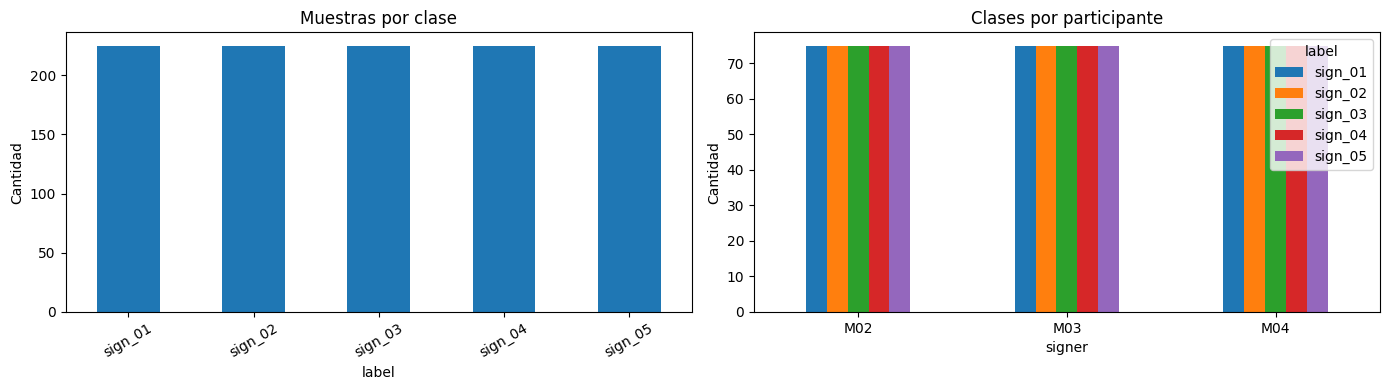

,label,file,shape,dtype,all_finite
0,sign_01,S01_M02_V01_C01_Clip076.npy,"(62, 1662)",float64,True
1,sign_01,S01_M02_V01_C01_Clip077.npy,"(83, 1662)",float64,True
2,sign_02,S02_M02_V01_C02_Clip376.npy,"(69, 1662)",float64,True
3,sign_02,S02_M02_V01_C02_Clip377.npy,"(58, 1662)",float64,True
4,sign_03,S03_M02_V01_C03_Clip676.npy,"(59, 1662)",float64,True
5,sign_03,S03_M02_V01_C03_Clip677.npy,"(72, 1662)",float64,True
6,sign_04,S04_M02_V01_C04_Clip1000.npy,"(55, 1662)",float64,True
7,sign_04,S04_M02_V01_C04_Clip976.npy,"(49, 1662)",float64,True
8,sign_05,S05_M02_V01_C04_Clip1276.npy,"(57, 1662)",float64,True
9,sign_05,S05_M02_V01_C04_Clip1277.npy,"(51, 1662)",float64,True


In [4]:
PUBLIC_SIGNERS_EXPECTED = ['M02', 'M03', 'M04']
found_signers = sorted(metadata['signer'].unique().tolist())
if found_signers != PUBLIC_SIGNERS_EXPECTED:
    raise RuntimeError(f'Firmantes públicos esperados {PUBLIC_SIGNERS_EXPECTED}; encontrados {found_signers}.')

class_counts = metadata['label'].value_counts().reindex(CLASS_NAMES, fill_value=0)
signer_class = pd.crosstab(metadata['signer'], metadata['label']).reindex(columns=CLASS_NAMES, fill_value=0)
view_counts = metadata['view'].value_counts(dropna=False)

print('Muestras por clase:')
display(class_counts.rename('n').to_frame())
print('Muestras por participante y clase:')
display(signer_class)
print('Muestras por vista:')
display(view_counts.rename('n').to_frame())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
class_counts.plot(kind='bar', ax=axes[0], title='Muestras por clase')
axes[0].set_ylabel('Cantidad'); axes[0].tick_params(axis='x', rotation=30)
signer_class.plot(kind='bar', ax=axes[1], title='Clases por participante')
axes[1].set_ylabel('Cantidad'); axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

shape_rows = []
for label in CLASS_NAMES:
    for row in metadata[metadata.label == label].head(2).itertuples():
        arr = np.load(row.path, allow_pickle=False)
        shape_rows.append({'label': label, 'file': Path(row.path).name,
                           'shape': arr.shape, 'dtype': str(arr.dtype),
                           'all_finite': bool(np.isfinite(arr).all())})
display(pd.DataFrame(shape_rows))

## 3. Landmarks, extracción base y normalización espacial 2D

Construimos `400` características base (`200` de posición normalizada por ancho de hombros + `200` de velocidades frame a frame) y conservamos explícitamente las máscaras crudas de presencia (`MASK_FEATURES = [197, 198, 199, 397, 398, 399]`).

In [5]:
# Rebanadas de la representación de MediaPipe Holistic (1662 features/frame)
POSE_SLICE = slice(0, 132)
FACE_SLICE = slice(132, 1536)
LEFT_HAND_SLICE = slice(1536, 1599)
RIGHT_HAND_SLICE = slice(1599, 1662)

BODY_JOINTS = [11, 12, 13, 14, 15, 16, 23, 24]  # hombros, codos, muñecas y caderas
FACE_JOINTS = [1, 33, 133, 362, 263, 61, 291, 13, 14, 70, 300]
BASE_FEATURE_DIM = 200
FEATURE_DIM = BASE_FEATURE_DIM * 2  # 400 (posición + velocidad)
MASK_FEATURES = [197, 198, 199, 397, 398, 399]

# Índices anulados en T10 v2: profundidad Z y coordenadas locales del rostro
Z_IDX = list(range(2, 132, 3)) + list(range(134, 164, 4))
FACE_IDX = list(range(164, 197))
ZERO_COLS = Z_IDX + FACE_IDX + [i + 200 for i in Z_IDX + FACE_IDX]

# Índices de coordenadas X e Y para rotación 2D durante entrenamiento
XY_X_BASE = list(range(0, 132, 3)) + list(range(132, 164, 4))
XY_X_IDX = XY_X_BASE + [i + 200 for i in XY_X_BASE]
XY_Y_IDX = [i + 1 for i in XY_X_IDX]


def load_landmark_array(path):
    """Carga un .npy y valida la forma esperada (T, 1662) sin NaN/Inf."""
    arr = np.load(path, allow_pickle=False)
    arr = np.asarray(arr, dtype=np.float32)
    if arr.ndim != 2:
        raise ValueError(f'{path}: esperaba matriz 2D, recibí {arr.shape}')
    if arr.shape[1] != 1662 and arr.shape[0] == 1662:
        arr = arr.T
    if arr.shape[1] != 1662:
        raise ValueError(f'{path}: esperaba 1662 características por frame, recibí {arr.shape}')
    arr = np.nan_to_num(arr, nan=0.0, posinf=0.0, neginf=0.0)
    if len(arr) < 2:
        raise ValueError(f'{path}: secuencia demasiado corta ({len(arr)} frames)')
    return arr


def landmarks_to_features(arr, target_len=SEQ_LEN, presence_override=None):
    """Construye (SEQ_LEN, 400) usando las máscaras de presencia observadas sobre video crudo."""
    t = len(arr)
    assert t == target_len

    pose = arr[:, POSE_SLICE].reshape(t, 33, 4)
    face = arr[:, FACE_SLICE].reshape(t, 468, 3)
    left_hand = arr[:, LEFT_HAND_SLICE].reshape(t, 21, 3)
    right_hand = arr[:, RIGHT_HAND_SLICE].reshape(t, 21, 3)

    # Escala corporal invariante a distancia: mediana del ancho de hombros
    left_shoulder = pose[:, 11, :3]
    right_shoulder = pose[:, 12, :3]
    torso_center = (left_shoulder + right_shoulder) / 2.0
    shoulder_width = np.linalg.norm(left_shoulder[:, :2] - right_shoulder[:, :2], axis=1)
    valid_widths = shoulder_width[shoulder_width > 1e-4]
    body_scale = max(float(np.median(valid_widths)) if len(valid_widths) else 1.0, 1e-3)

    def hand_features(hand, observed=None):
        geometric_present = (np.max(np.abs(hand), axis=(1, 2)) > 1e-6).astype(np.float32)
        present = geometric_present if observed is None else observed
        wrist = hand[:, 0, :]
        local = (hand - wrist[:, None, :]) / body_scale
        global_wrist = (wrist - torso_center) / body_scale
        local[geometric_present == 0] = 0.0
        global_wrist[geometric_present == 0] = 0.0
        return local.reshape(t, -1), global_wrist, present

    left_local, left_wrist, left_present = hand_features(left_hand, None if presence_override is None else presence_override[:, 0])
    right_local, right_wrist, right_present = hand_features(right_hand, None if presence_override is None else presence_override[:, 1])

    body_xyz = (pose[:, BODY_JOINTS, :3] - torso_center[:, None, :]) / body_scale
    body_visibility = pose[:, BODY_JOINTS, 3:4]
    body_features = np.concatenate([body_xyz, body_visibility], axis=2).reshape(t, -1)

    selected_face = face[:, FACE_JOINTS, :]
    nose = face[:, 1, :]
    eye_width = np.linalg.norm(face[:, 33, :2] - face[:, 263, :2], axis=1)
    valid_eye_widths = eye_width[eye_width > 1e-4]
    face_scale = max(float(np.median(valid_eye_widths)) if len(valid_eye_widths) else 1.0, 1e-3)
    face_present = (np.max(np.abs(face), axis=(1, 2)) > 1e-6).astype(np.float32)
    face_local = (selected_face - nose[:, None, :]) / face_scale
    face_local[face_present == 0] = 0.0
    if presence_override is not None:
        face_present = presence_override[:, 2]
    face_features = face_local.reshape(t, -1)

    base = np.concatenate([
        left_local, right_local,
        left_wrist, right_wrist,
        body_features, face_features,
        left_present[:, None], right_present[:, None], face_present[:, None]
    ], axis=1).astype(np.float32)

    velocity = np.diff(base, axis=0, prepend=base[:1]).astype(np.float32)
    velocity[:, -3:] = 0.0
    features = np.concatenate([base, velocity], axis=1).astype(np.float32)
    return np.nan_to_num(features, nan=0.0, posinf=0.0, neginf=0.0)

example_path = Path(metadata.iloc[0]['path'])
example_raw = load_landmark_array(example_path)
print('Archivo de ejemplo:', example_path.name, '| Forma original:', example_raw.shape)

Archivo de ejemplo: S01_M02_V01_C01_Clip076.npy | Forma original: (62, 1662)


### 3a. Espejo anatómico (lateralidad)

Refleja el eje `x` (`1 - x`) y permuta mano izquierda/derecha y articulaciones simétricas para resolver la diferencia entre firmantes zurdos (`M02`) y diestros (`M03`, `M04`).

In [6]:
PAIRS = [(1,4),(2,5),(3,6),(7,8),(9,10),(11,12),(13,14),(15,16),(17,18),(19,20),(21,22),(23,24),(25,26),(27,28),(29,30),(31,32)]
FACE_PAIRS = [(33,263),(133,362),(61,291),(70,300)]


def _flipx(block):
    """Invierte x -> 1 - x solo en frames donde el bloque existe."""
    block = block.copy()
    present = np.abs(block).max(axis=2) > 1e-6
    block[..., 0] = np.where(present, 1.0 - block[..., 0], 0.0)
    return block


def mirror_raw(arr):
    """Genera la secuencia espejada intercambiando mano izquierda y derecha."""
    t = len(arr)
    pose = _flipx(arr[:, POSE_SLICE].reshape(t, 33, 4))
    face = _flipx(arr[:, FACE_SLICE].reshape(t, 468, 3))
    lh = _flipx(arr[:, LEFT_HAND_SLICE].reshape(t, 21, 3))
    rh = _flipx(arr[:, RIGHT_HAND_SLICE].reshape(t, 21, 3))
    for i, j in PAIRS:
        pose[:, [i, j]] = pose[:, [j, i]]
    for i, j in FACE_PAIRS:
        face[:, [i, j]] = face[:, [j, i]]
    return np.concatenate([pose.reshape(t, -1), face.reshape(t, -1),
                           rh.reshape(t, -1), lh.reshape(t, -1)], axis=1).astype(np.float32)

assert np.allclose(mirror_raw(mirror_raw(example_raw)), example_raw, atol=1e-5)
print('Espejo anatómico OK (doble espejo = original).')

Espejo anatómico OK (doble espejo = original).


### 3b. Características adicionales (36): ángulos de dedos y distancias 2D

Calcula los `30` ángulos internos de flexión de los 10 dedos y las `6` distancias 2D normalizadas muñeca–nariz, muñeca–boca y muñeca–pecho (`INPUT_DIM = 436`).

In [7]:
EXTRA_DIM = 36
INPUT_DIM = FEATURE_DIM + EXTRA_DIM  # 436
FINGER_CHAINS = [(0, 1, 2, 3, 4), (0, 5, 6, 7, 8), (0, 9, 10, 11, 12), (0, 13, 14, 15, 16), (0, 17, 18, 19, 20)]


def _joint_angles(hand):
    """Calcula 15 ángulos internos por mano normalizados en [0, 1]."""
    out = []
    for chain in FINGER_CHAINS:
        for k in range(1, 4):
            p_prev, p_joint, p_next = hand[:, chain[k - 1]], hand[:, chain[k]], hand[:, chain[k + 1]]
            v1, v2 = p_prev - p_joint, p_next - p_joint
            denom = np.maximum(np.linalg.norm(v1, axis=1) * np.linalg.norm(v2, axis=1), 1e-6)
            cos = np.clip(np.sum(v1 * v2, axis=1) / denom, -1.0, 1.0)
            out.append(np.arccos(cos) / np.pi)
    return np.stack(out, axis=1)


def extra_features(arr):
    """Extrae 36 rasgos geométricos extra: ang_izq(15), ang_der(15), dist_izq(3), dist_der(3)."""
    t = len(arr)
    pose = arr[:, POSE_SLICE].reshape(t, 33, 4)
    face = arr[:, FACE_SLICE].reshape(t, 468, 3)
    hands = [arr[:, LEFT_HAND_SLICE].reshape(t, 21, 3), arr[:, RIGHT_HAND_SLICE].reshape(t, 21, 3)]

    widths = np.linalg.norm(pose[:, 11, :2] - pose[:, 12, :2], axis=1)
    valid = widths[widths > 1e-4]
    scale = max(float(np.median(valid)) if len(valid) else 1.0, 1e-3)
    chest = pose[:, [11, 12, 23, 24], :2].mean(axis=1)
    face_present = np.max(np.abs(face), axis=(1, 2)) > 1e-6
    nose = face[:, 1, :2]
    mouth = (face[:, 13, :2] + face[:, 14, :2]) / 2.0

    blocks_ang, blocks_dist = [], []
    for hand in hands:
        present = np.max(np.abs(hand), axis=(1, 2)) > 1e-6
        ang = _joint_angles(hand)
        wrist = hand[:, 0, :2]
        dist = np.stack([np.linalg.norm(wrist - nose, axis=1),
                         np.linalg.norm(wrist - mouth, axis=1),
                         np.linalg.norm(wrist - chest, axis=1)], axis=1) / scale
        dist[~face_present, :2] = 0.0
        ang[~present] = 0.0
        dist[~present] = 0.0
        blocks_ang.append(ang)
        blocks_dist.append(dist)
    out = np.concatenate([blocks_ang[0], blocks_ang[1], blocks_dist[0], blocks_dist[1]], axis=1)
    return np.nan_to_num(out, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)

### 3c. Recorte activo y remuestreo consciente de ausencias (`mask_aware`)

1. **`trim_active_motion_pose`:** recorta frames en reposo antes y después de la seña detectando cuándo las muñecas se elevan sobre su posición basal.
2. **`resample_landmarks_mask_aware`:** detecta presencia sobre frames originales, repara solo huecos internos cortos (`<= 3` frames) y remuestrea a `SEQ_LEN = 32` frames sin promediar coordenadas válidas con ceros.
3. **`full_features`:** ensambla las `436` dimensiones y anula `ZERO_COLS` (profundidad `Z` y coordenadas locales del rostro).

In [8]:
def raw_presence_masks(raw):
    """Retorna 4 flags booleanos (pose, rostro, mano izq, mano der) por frame original."""
    t = len(raw)
    pose = raw[:, POSE_SLICE].reshape(t, 33, 4)
    face = raw[:, FACE_SLICE].reshape(t, 468, 3)
    lh = raw[:, LEFT_HAND_SLICE].reshape(t, 21, 3)
    rh = raw[:, RIGHT_HAND_SLICE].reshape(t, 21, 3)
    return np.stack([
        np.max(np.abs(pose[:, :, :3]), axis=(1, 2)) > 1e-6,
        np.max(np.abs(face), axis=(1, 2)) > 1e-6,
        np.max(np.abs(lh), axis=(1, 2)) > 1e-6,
        np.max(np.abs(rh), axis=(1, 2)) > 1e-6,
    ], axis=1)


def fill_short_missing_runs(block, observed, max_gap=MAX_INTERPOLATION_GAP):
    """Imputa solo huecos interiores de hasta max_gap frames entre observaciones válidas."""
    block = np.asarray(block, dtype=np.float32)
    observed = np.asarray(observed, dtype=bool)
    out = block.copy()
    usable = observed.copy()
    valid_indices = np.flatnonzero(observed)
    for a, b in zip(valid_indices[:-1], valid_indices[1:]):
        count = int(b - a - 1)
        if 0 < count <= max_gap:
            for i in range(a + 1, b):
                w = (i - a) / (b - a)
                out[i] = (1.0 - w) * out[a] + w * out[b]
                usable[i] = True
    return out, usable


def resample_masked_block(block, usable, positions):
    """Interpola pares utilizables evitando mezclar frames válidos con ceros."""
    lo = np.floor(positions).astype(np.int64)
    hi = np.minimum(lo + 1, len(block) - 1)
    alpha = (positions - lo).astype(np.float32)
    shape = (len(positions),) + (1,) * (block.ndim - 1)
    w = alpha.reshape(shape)
    mix = (1.0 - w) * block[lo] + w * block[hi]
    both = usable[lo] & usable[hi]
    choose_lo = usable[lo] & (~usable[hi]) & (alpha < 0.5)
    choose_hi = usable[hi] & (~usable[lo]) & (alpha >= 0.5)
    out = np.zeros_like(mix)
    out[both] = mix[both]
    out[choose_lo] = block[lo[choose_lo]]
    out[choose_hi] = block[hi[choose_hi]]
    return out.astype(np.float32)


def resample_landmarks_mask_aware(raw, target_len=SEQ_LEN):
    """Remuestrea la secuencia a SEQ_LEN frames conservando las máscaras observadas originales."""
    raw = np.asarray(raw, dtype=np.float32)
    observed = raw_presence_masks(raw)
    positions = np.linspace(0, len(raw) - 1, target_len, dtype=np.float32)
    nearest = np.clip(np.floor(positions + 0.5).astype(np.int64), 0, len(raw) - 1)

    specs = [(POSE_SLICE, 0), (FACE_SLICE, 1), (LEFT_HAND_SLICE, 2), (RIGHT_HAND_SLICE, 3)]
    result = np.zeros((target_len, 1662), dtype=np.float32)
    for sl, j in specs:
        repaired, usable = fill_short_missing_runs(raw[:, sl], observed[:, j])
        result[:, sl] = resample_masked_block(repaired, usable, positions)

    original_masks = observed[nearest][:, [2, 3, 1]].astype(np.float32)
    return result, original_masks


def trim_active_motion_pose(raw, rest_rise=0.3, min_active=3, margin=2):
    """Recorta frames inactivos al inicio y final según la elevación de muñecas normalizada por hombros."""
    t = len(raw)
    if t <= 10:
        return raw
    pose = raw[:, POSE_SLICE].reshape(t, 33, 4)
    ls, rs = pose[:, 11, :2], pose[:, 12, :2]
    both = (np.abs(ls).sum(axis=1) > 1e-6) & (np.abs(rs).sum(axis=1) > 1e-6)
    if not both.any():
        return raw
    width = max(float(np.linalg.norm(ls[both] - rs[both], axis=-1).mean()), 1e-3)
    wrists = pose[:, [15, 16], :2]
    w_ok = np.abs(wrists).sum(axis=2) > 1e-6
    if not w_ok.any():
        return raw
    wrists_y = np.where(w_ok, wrists[:, :, 1] / width, np.nan)
    rise = np.nanpercentile(wrists_y, 90, axis=0) - wrists_y
    active = (np.nan_to_num(rise, nan=0.0) > rest_rise).any(axis=1)
    sustained = np.convolve(active.astype(np.int32), np.ones(min_active, dtype=np.int32), mode='valid') == min_active
    starts = np.flatnonzero(sustained)
    if len(starts) == 0:
        return raw
    first = max(int(starts[0]) - margin, 0)
    last = min(int(starts[-1]) + min_active + margin, t)
    return raw[first:last] if (last - first) >= 6 else raw


def full_features(raw, seq_len=SEQ_LEN):
    """Pipeline completo por muestra: recorte activo -> resampleo mask_aware -> features 2D sin rostro."""
    raw = trim_active_motion_pose(raw, rest_rise=0.3, min_active=3, margin=2)
    arr, original_masks = resample_landmarks_mask_aware(raw, seq_len)
    base = landmarks_to_features(arr, seq_len, presence_override=original_masks)
    out = np.concatenate([base, extra_features(arr)], axis=1)
    out = np.nan_to_num(out, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)
    out[:, ZERO_COLS] = 0.0
    assert out.shape == (seq_len, INPUT_DIM) and np.isfinite(out).all()
    return out

### 3d. Pruebas de integridad: `mask_aware`, huecos largos y espejo

In [9]:
def run_preprocessing_unit_tests():
    raw = np.zeros((7, 1662), dtype=np.float32)
    pose = raw[:, POSE_SLICE].reshape(7, 33, 4)
    pose[:, 11, :2] = [0.4, 0.4]
    pose[:, 12, :2] = [0.6, 0.4]
    face = raw[:, FACE_SLICE].reshape(7, 468, 3)
    face[:, 1, :2] = [0.5, 0.2]
    face[:, 33, :2] = [0.45, 0.2]
    face[:, 263, :2] = [0.55, 0.2]
    lh = raw[:, LEFT_HAND_SLICE].reshape(7, 21, 3)
    lh[[0, 1, 4, 5, 6], :, 0] = 0.3
    lh[[0, 1, 4, 5, 6], :, 1] = 0.5
    observed = raw_presence_masks(raw)
    assert observed[:, 2].tolist() == [True, True, False, False, True, True, True]
    resampled, masks = resample_landmarks_mask_aware(raw, target_len=7)
    assert masks[:, 0].tolist() == [1., 1., 0., 0., 1., 1., 1.]
    assert np.abs(resampled[2:4, LEFT_HAND_SLICE]).sum() > 0
    feat_new = full_features(raw, 7)
    assert np.allclose(feat_new[:, 197], masks[:, 0])
    assert np.allclose(feat_new[:, ZERO_COLS], 0.0)
    assert np.all(np.isfinite(feat_new))
    print('Pruebas sintéticas OK: máscaras crudas, reconstrucción corta, proyección 2D y espejo.')

run_preprocessing_unit_tests()
_f = full_features(example_raw)
print('Archivo real:', example_path.name, '| Características:', _f.shape, '| Finitos:', bool(np.isfinite(_f).all()))

Pruebas sintéticas OK: máscaras crudas, reconstrucción corta, proyección 2D y espejo.
Archivo real: S01_M02_V01_C01_Clip076.npy | Características: (32, 436) | Finitos: True


## 4. Diagnóstico en entrenamiento: disponibilidad de manos por vista/clase

Medimos la fracción de detección **sobre frames originales** en entrenamiento público (`M02`, `M03`, `M04`), sin leer test.

In [10]:
def diagnose_public_presence(meta_df):
    rows = []
    for r in tqdm(meta_df.itertuples(index=False), total=len(meta_df), desc='Calidad de detección (train)'):
        raw = load_landmark_array(r.path)
        pres = raw_presence_masks(raw)
        rows.append({
            'video_id': r.video_id, 'signer': r.signer, 'view': r.view,
            'label': r.label, 'frames': len(raw),
            'pose_seen': float(pres[:, 0].mean()), 'face_seen': float(pres[:, 1].mean()),
            'left_seen': float(pres[:, 2].mean()), 'right_seen': float(pres[:, 3].mean())
        })
    return pd.DataFrame(rows)

presence_df = diagnose_public_presence(metadata)
presence_df.to_csv(OUT_DIR / 'public_presence_diagnostics.csv', index=False)
print('Detección media por participante:')
display(presence_df.groupby('signer')[['left_seen', 'right_seen', 'face_seen']].mean().round(3))
print('Detección por participante/vista en sign_05:')
display(presence_df[presence_df.label == 'sign_05'].groupby(['signer','view'])[['left_seen','right_seen','face_seen','frames']].mean().round(3))

Calidad de detección (train):   0%|          | 0/1125 [00:00<?, ?it/s]

Detección media por participante:


,left_seen,right_seen,face_seen
signer,,,
M02,0.583,0.191,0.990
M03,0.264,0.600,0.986
M04,0.283,0.637,0.990


Detección por participante/vista en sign_05:


left_seen  right_seen  face_seen  frames
signer view                                          
M02    V01       0.684       0.000      1.000   49.40
       V02       0.578       0.231      1.000   48.72
       V03       0.551       0.001      0.938   48.20
M03    V01       0.999       0.647      1.000   48.40
       V02       0.000       0.512      1.000   46.68
       V03       0.285       0.491      1.000   44.84
M04    V01       0.000       0.598      1.000   57.56
       V02       0.980       0.981      0.991   53.64
       V03       0.097       0.505      1.000   59.68

## 5. Procesar las 1.125 secuencias, su espejo y segmentos temporales

Construimos el tensor `X` de forma `(1125, 32, 436)`, su copia espejada `X_mirror` y las representaciones por 4 tramos (`X_vec`, `X_vec_mir`) para el modelo lineal.

In [11]:
def build_feature_tensor(meta_df, mirror=False, seq_len=SEQ_LEN):
    """Procesa las muestras etiquetadas (opcionalmente espejadas) y devuelve X de forma (N, SEQ_LEN, 436)."""
    sequences = []
    desc = 'Espejando landmarks' if mirror else 'Procesando landmarks'
    for row in tqdm(meta_df.itertuples(index=False), total=len(meta_df), desc=desc):
        raw = load_landmark_array(row.path)
        if mirror:
            raw = mirror_raw(raw)
        sequences.append(full_features(raw, seq_len))
    return np.stack(sequences).astype(np.float32)


def seq_to_segment_vector(X_seq, n_segments=N_SEGMENTS):
    """Convierte (N, T, D) en vector plano de n_segments medias por tramo + 1 desviación estándar global."""
    segs = np.array_split(X_seq, n_segments, axis=1)
    means = [s.mean(axis=1) for s in segs]
    std = X_seq.std(axis=1)
    return np.concatenate(means + [std], axis=1).astype(np.float32)


X = build_feature_tensor(metadata)
X_mirror = build_feature_tensor(metadata, mirror=True)
X_vec = seq_to_segment_vector(X, N_SEGMENTS)
X_vec_mir = seq_to_segment_vector(X_mirror, N_SEGMENTS)
y = metadata['y'].to_numpy(dtype=np.int64)
signer_values_all = metadata['signer'].to_numpy()
SIGNERS = sorted(metadata['signer'].unique())
assert X.shape == (len(metadata), SEQ_LEN, INPUT_DIM) and X_mirror.shape == X.shape

print('X:', X.shape, X.dtype, '| X_mirror:', X_mirror.shape, '| X_vec:', X_vec.shape)
print('Uso aproximado de memoria (MB):', round((X.nbytes + X_mirror.nbytes) / 1024**2, 1))
print('Distribución de etiquetas:', Counter(y.tolist()))
metadata.to_csv(OUT_DIR / 'train_metadata.csv', index=False)

Procesando landmarks:   0%|          | 0/1125 [00:00<?, ?it/s]

Espejando landmarks:   0%|          | 0/1125 [00:00<?, ?it/s]

X: (1125, 32, 436) float32 | X_mirror: (1125, 32, 436) | X_vec: (1125, 2180)
Uso aproximado de memoria (MB): 119.8
Distribución de etiquetas: Counter({0: 225, 1: 225, 2: 225, 3: 225, 4: 225})


## 6. Escalado y métricas (Accuracy Top-1 y macro-F1)

El escalador se ajusta exclusivamente sobre el entrenamiento de cada fold, sin fuga desde el participante reservado.

In [12]:
def fit_sequence_scaler(X_train):
    """Ajusta media y desviación estándar por característica usando solo X_train."""
    flat = X_train.reshape(-1, X_train.shape[-1]).astype(np.float64)
    mean = flat.mean(axis=0).astype(np.float32)
    std = flat.std(axis=0).astype(np.float32)
    std[std < 1e-5] = 1.0
    return {'mean': mean, 'std': std}


def apply_sequence_scaler(X_data, scaler):
    return ((X_data - scaler['mean'][None, None, :]) / scaler['std'][None, None, :]).astype(np.float32)


def calculate_metrics(y_true, y_pred):
    return {
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'macro_f1': float(f1_score(y_true, y_pred, average='macro', zero_division=0)),
    }


def print_confusion(y_true, y_pred, title='Matriz de confusión'):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(CLASS_NAMES))))
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, cmap='Blues')
    ax.set_title(title)
    ax.set_xlabel('Predicción'); ax.set_ylabel('Etiqueta real')
    ax.set_xticks(range(5), CLASS_NAMES, rotation=35, ha='right')
    ax.set_yticks(range(5), CLASS_NAMES)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, str(cm[i, j]), ha='center', va='center')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout(); plt.show()
    return cm

## 7. Arquitecturas del Ensamble (137.512 parámetros en total)

Definimos las tres arquitecturas complementarias que se promedian en partes iguales (`1/3 + 1/3 + 1/3`):
1. **`LSC5_Transformer` (`84.034` parámetros):** proyección por ramas anatómicas (`40/20/4`), encoder de 2 capas (`d_model=64`, `4` cabezas) y *attention + mean pooling*.
2. **`LSC5_CNN1D` (`38.213` parámetros):** convoluciones 1D residuales *depthwise-separable* con kernels `5` y `3`.
3. **`LinearSegmentModel` (`15.265` parámetros):** clasificador lineal regularizado sobre estadísticas de 4 tramos temporales.

In [13]:
HAND_STREAM_IDX = list(range(0, 132)) + list(range(200, 332)) + [197, 198] + list(range(400, 436))
BODY_STREAM_IDX = list(range(132, 164)) + list(range(332, 364))
FACE_STREAM_IDX = list(range(164, 197)) + list(range(364, 397)) + [199]
_all_idx = HAND_STREAM_IDX + BODY_STREAM_IDX + FACE_STREAM_IDX
assert len(set(_all_idx)) == len(_all_idx) and max(_all_idx) < INPUT_DIM


def _branch(n_in, n_out):
    """Proyección de una rama anatómica: Linear -> LayerNorm -> GELU."""
    return nn.Sequential(nn.Linear(n_in, n_out), nn.LayerNorm(n_out), nn.GELU())


class LSC5_Transformer(nn.Module):
    """Transformer compacto de 3 ramas anatómicas (84.034 parámetros)."""
    def __init__(self, dropout=DROPOUT, num_classes=5):
        super().__init__()
        self.register_buffer('hand_idx', torch.tensor(HAND_STREAM_IDX, dtype=torch.long))
        self.register_buffer('body_idx', torch.tensor(BODY_STREAM_IDX, dtype=torch.long))
        self.register_buffer('face_idx', torch.tensor(FACE_STREAM_IDX, dtype=torch.long))
        self.hand_proj = _branch(len(HAND_STREAM_IDX), HAND_DIM)
        self.body_proj = _branch(len(BODY_STREAM_IDX), BODY_DIM)
        self.face_proj = _branch(len(FACE_STREAM_IDX), FACE_DIM)
        self.fusion_norm = nn.LayerNorm(D_MODEL)
        self.pos_embed = nn.Parameter(torch.zeros(1, SEQ_LEN, D_MODEL))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        self.embed_dropout = nn.Dropout(dropout)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=D_MODEL, nhead=N_HEADS, dim_feedforward=FFN_DIM,
            dropout=dropout, activation='gelu', batch_first=True, norm_first=True
        )
        self.encoder = nn.TransformerEncoder(
            encoder_layer, num_layers=N_LAYERS, norm=nn.LayerNorm(D_MODEL), enable_nested_tensor=False
        )
        self.attn_pool = nn.Linear(D_MODEL, 1)
        self.classifier = nn.Sequential(
            nn.LayerNorm(D_MODEL * 2), nn.Dropout(dropout), nn.Linear(D_MODEL * 2, num_classes)
        )

    def forward(self, x):
        tokens = torch.cat([
            self.hand_proj(x.index_select(2, self.hand_idx)),
            self.body_proj(x.index_select(2, self.body_idx)),
            self.face_proj(x.index_select(2, self.face_idx))
        ], dim=-1)
        tokens = self.embed_dropout(self.fusion_norm(tokens) + self.pos_embed)
        features = self.encoder(tokens)
        weights = torch.softmax(self.attn_pool(features), dim=1)
        attended = torch.sum(features * weights, dim=1)
        return self.classifier(torch.cat([attended, features.mean(dim=1)], dim=1))


class LSC5_CNN1D(nn.Module):
    """CNN 1D compacta (38.213 parámetros) con convoluciones depthwise-separable residuales."""
    def __init__(self, in_dim=INPUT_DIM, hidden=64, dropout=DROPOUT, num_classes=5):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv1d(in_dim, hidden, kernel_size=1), nn.BatchNorm1d(hidden), nn.GELU(), nn.Dropout(dropout)
        )
        self.block1 = nn.Sequential(
            nn.Conv1d(hidden, hidden, kernel_size=5, padding=2, groups=hidden),
            nn.Conv1d(hidden, hidden, kernel_size=1), nn.BatchNorm1d(hidden), nn.GELU(), nn.Dropout(dropout)
        )
        self.block2 = nn.Sequential(
            nn.Conv1d(hidden, hidden, kernel_size=3, padding=1, groups=hidden),
            nn.Conv1d(hidden, hidden, kernel_size=1), nn.BatchNorm1d(hidden), nn.GELU(), nn.Dropout(dropout)
        )
        self.head = nn.Sequential(nn.LayerNorm(hidden * 2), nn.Dropout(dropout), nn.Linear(hidden * 2, num_classes))

    def forward(self, x):
        h = self.stem(x.transpose(1, 2))
        h = h + self.block1(h)
        h = h + self.block2(h)
        pooled = torch.cat([h.mean(dim=-1), h.amax(dim=-1)], dim=1)
        return self.head(pooled)


class LinearSegmentModel(nn.Module):
    """Modelo lineal por 4 tramos temporales + desviación estándar global (15.265 parámetros)."""
    def __init__(self, in_dim, num_classes=5, dropout=LIN_DROPOUT):
        super().__init__()
        self.norm = nn.BatchNorm1d(in_dim)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(in_dim, num_classes)

    def forward(self, x):
        return self.fc(self.drop(self.norm(x)))


p_trans = sum(p.numel() for p in LSC5_Transformer().parameters())
p_cnn = sum(p.numel() for p in LSC5_CNN1D().parameters())
p_lin = sum(p.numel() for p in LinearSegmentModel(INPUT_DIM * (N_SEGMENTS + 1)).parameters())
print(f'Parámetros -> Transformer: {p_trans:,} | CNN1D: {p_cnn:,} | Lineal: {p_lin:,} | Total: {p_trans + p_cnn + p_lin:,}')

Parámetros -> Transformer: 84,034 | CNN1D: 38,213 | Lineal: 15,265 | Total: 137,512


## 8. Entrenamiento y augmentación (secuencial y por tramos con rotación 2D)

Incluye aumento temporal (`gamma ∈ [0.90, 1.10]`), rotación 2D (`±10°`), ruido gaussiano controlado y *hand-drop* aleatorio para las redes secuenciales, así como rotación 2D por batch para el modelo lineal por 4 tramos.

In [14]:
def batch_rotate_2d_torch(xb, max_deg=10.0, p=0.70):
    """Aplica rotación 2D aleatoria (±max_deg) por muestra en un batch (B, T, D)."""
    B = xb.shape[0]
    device = xb.device
    apply_mask = torch.rand(B, device=device) < p
    if not apply_mask.any():
        return xb
    xb = xb.clone()
    angles = (torch.rand(B, device=device) * 2.0 - 1.0) * math.radians(max_deg)
    angles = torch.where(apply_mask, angles, torch.zeros_like(angles))
    c = torch.cos(angles).view(B, 1, 1)
    s = torch.sin(angles).view(B, 1, 1)
    vx = xb[:, :, XY_X_IDX]
    vy = xb[:, :, XY_Y_IDX]
    xb[:, :, XY_X_IDX] = c * vx - s * vy
    xb[:, :, XY_Y_IDX] = s * vx + c * vy
    return xb


def batch_seq_to_segment_vector_torch(xb, n_segments=N_SEGMENTS):
    chunks = torch.tensor_split(xb, n_segments, dim=1)
    means = [c.mean(dim=1) for c in chunks]
    std = xb.std(dim=1, unbiased=False)
    return torch.cat(means + [std], dim=1)


class SequenceDataset(Dataset):
    """Dataset de secuencias con time-warping, rotación 2D, ruido y hand-drop."""
    def __init__(self, X_data, y_data, augment=False):
        self.X = torch.from_numpy(np.asarray(X_data, dtype=np.float32))
        self.y = torch.from_numpy(np.asarray(y_data, dtype=np.int64))
        self.augment = augment

    def __len__(self):
        return len(self.y)

    def _augment_sequence(self, x):
        if random.random() < 0.65:
            t = x.shape[0]
            gamma = random.uniform(0.90, 1.10)
            positions = (np.linspace(0, 1, t, dtype=np.float32) ** gamma) * (t - 1)
            lo = np.floor(positions).astype(np.int64)
            hi = np.minimum(lo + 1, t - 1)
            alpha = (positions - lo)[:, None]
            old_x = x
            x = x[lo] * (1.0 - alpha) + x[hi] * alpha
            near = np.clip(np.floor(positions + 0.5).astype(int), 0, t - 1)
            x[:, MASK_FEATURES] = old_x[near][:, MASK_FEATURES]

        if random.random() < 0.70:
            ang = math.radians(random.uniform(-10.0, 10.0))
            c, s = math.cos(ang), math.sin(ang)
            vx, vy = x[:, XY_X_IDX].copy(), x[:, XY_Y_IDX].copy()
            x[:, XY_X_IDX] = c * vx - s * vy
            x[:, XY_Y_IDX] = s * vx + c * vy

        if random.random() < 0.70:
            noise = np.random.normal(0, 0.015, size=x.shape).astype(np.float32)
            noise[:, MASK_FEATURES] = 0.0
            x = x + noise

        if random.random() < 0.25:
            drop_frames = np.random.rand(x.shape[0]) < 0.30
            if random.random() < 0.5:
                lh_cols = list(range(0, 63)) + list(range(126, 129)) + list(range(200, 263)) + list(range(326, 329)) + list(range(400, 415)) + list(range(430, 433))
                x[np.ix_(drop_frames, lh_cols)] = 0.0
            else:
                rh_cols = list(range(63, 126)) + list(range(129, 132)) + list(range(263, 326)) + list(range(329, 332)) + list(range(415, 430)) + list(range(433, 436))
                x[np.ix_(drop_frames, rh_cols)] = 0.0
        return x.astype(np.float32)

    def __getitem__(self, idx):
        x = self.X[idx].numpy().copy()
        if self.augment:
            x = self._augment_sequence(x)
        return torch.from_numpy(x), self.y[idx]


def predict_seq_model(model, scaler, X_raw, X_mir=None, batch_size=64):
    """Predice probabilidades promediando secuencia original y espejada (TTA)."""
    model.eval()
    def _run(X_in):
        X_s = apply_sequence_scaler(X_in, scaler)
        loader = DataLoader(SequenceDataset(X_s, np.zeros(len(X_s), dtype=np.int64), augment=False),
                            batch_size=batch_size, shuffle=False, num_workers=0)
        outs = []
        with torch.no_grad():
            for xb, _ in loader:
                logits = model(xb.to(DEVICE, non_blocking=True))
                outs.append(torch.softmax(logits.float(), dim=1).cpu().numpy())
        return np.concatenate(outs, axis=0)
    p = _run(X_raw)
    if MIRROR_TTA and X_mir is not None:
        p = 0.5 * (p + _run(X_mir))
    return p


def fit_seq_model(model_cls, X_train_raw, y_train, X_valid_raw=None, y_valid=None,
                  max_epochs=MAX_EPOCHS, patience=PATIENCE, seed=SEED, lr=LR):
    """Entrena Transformer o CNN1D con AdamW, CosineAnnealingLR y early stopping."""
    seed_everything(seed)
    scaler = fit_sequence_scaler(X_train_raw)
    pin = DEVICE.type == 'cuda'
    train_loader = DataLoader(SequenceDataset(apply_sequence_scaler(X_train_raw, scaler), y_train, augment=True),
                              batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=pin)
    has_valid = X_valid_raw is not None and y_valid is not None
    if has_valid:
        valid_loader = DataLoader(SequenceDataset(apply_sequence_scaler(X_valid_raw, scaler), y_valid, augment=False),
                                  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)

    model = model_cls().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max_epochs)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.03)
    amp_enabled = bool(USE_AMP and DEVICE.type == 'cuda')
    try:
        grad_scaler = torch.amp.GradScaler('cuda', enabled=amp_enabled)
    except (AttributeError, TypeError):
        grad_scaler = torch.cuda.amp.GradScaler(enabled=amp_enabled)

    best_epoch, best_acc, best_loss = max_epochs, -1.0, float('inf')
    best_state, no_improve, history = None, 0, []

    for epoch in range(1, max_epochs + 1):
        model.train()
        running_loss, seen, train_correct = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            if amp_enabled:
                with torch.autocast(device_type='cuda', enabled=True):
                    logits = model(xb)
                    loss = criterion(logits, yb)
                grad_scaler.scale(loss).backward()
                grad_scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                grad_scaler.step(optimizer)
                grad_scaler.update()
            else:
                logits = model(xb)
                loss = criterion(logits, yb)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            running_loss += float(loss.item()) * len(yb)
            seen += len(yb)
            # Accuracy de los mismos lotes aumentados usados para entrenar.
            train_correct += int((logits.detach().argmax(dim=1) == yb).sum().item())
        row = {'epoch': epoch, 'train_loss': running_loss / max(seen, 1),
               'train_accuracy': train_correct / max(seen, 1)}

        if has_valid:
            model.eval()
            val_loss_sum, val_seen, val_pred, val_true = 0.0, 0, [], []
            with torch.no_grad():
                for xb, yb in valid_loader:
                    xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
                    logits = model(xb)
                    loss = criterion(logits, yb)
                    val_loss_sum += float(loss.item()) * len(yb)
                    val_seen += len(yb)
                    val_pred.extend(logits.argmax(dim=1).cpu().numpy().tolist())
                    val_true.extend(yb.cpu().numpy().tolist())
            val_loss = val_loss_sum / max(val_seen, 1)
            val_acc = accuracy_score(val_true, val_pred)
            row.update({'val_loss': val_loss, 'val_accuracy': val_acc})
            improved = (val_acc > best_acc + 1e-6) or (abs(val_acc - best_acc) <= 1e-6 and val_loss < best_loss)
            if improved:
                best_acc, best_loss, best_epoch = float(val_acc), float(val_loss), epoch
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                no_improve = 0
            else:
                no_improve += 1
        else:
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        history.append(row)
        scheduler.step()
        if has_valid and no_improve >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, scaler, int(best_epoch), pd.DataFrame(history)


def fit_linear_segment(X_seq_tr, y_tr, seed, epochs=LIN_EPOCHS, rotate_2d=True):
    """Entrena el modelo lineal por 4 tramos aplicando rotación 2D aleatoria en cada batch."""
    seed_everything(seed)
    in_dim = X_seq_tr.shape[2] * (N_SEGMENTS + 1)
    dl = DataLoader(TensorDataset(torch.from_numpy(X_seq_tr), torch.from_numpy(y_tr)),
                    batch_size=BATCH_SIZE, shuffle=True)
    net = LinearSegmentModel(in_dim, len(CLASS_NAMES)).to(DEVICE)
    opt = torch.optim.AdamW(net.parameters(), lr=LIN_LR, weight_decay=LIN_WD)
    crit = nn.CrossEntropyLoss(label_smoothing=0.03)
    net.train()
    history = []
    for epoch in range(1, epochs+1):
        running_loss, seen, correct = 0.0, 0, 0
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            if rotate_2d:
                xb = batch_rotate_2d_torch(xb, max_deg=10.0, p=0.70)
            xvec = batch_seq_to_segment_vector_torch(xb, N_SEGMENTS)
            opt.zero_grad()
            logits = net(xvec)
            loss = crit(logits, yb)
            loss.backward()
            opt.step()
            running_loss += float(loss.detach().item()) * len(yb)
            seen += len(yb)
            correct += int((logits.detach().argmax(dim=1) == yb).sum().item())
        history.append({'epoch': epoch, 'train_loss': running_loss / seen,
                        'train_accuracy': correct / seen})
    net.eval()
    return net, pd.DataFrame(history)


def predict_linear_segment(net, X_v, X_v_mir=None):
    net.eval()
    with torch.no_grad():
        p1 = torch.softmax(net(torch.from_numpy(X_v).to(DEVICE)), dim=1).cpu().numpy()
        if MIRROR_TTA and X_v_mir is not None:
            p2 = torch.softmax(net(torch.from_numpy(X_v_mir).to(DEVICE)), dim=1).cpu().numpy()
            return 0.5 * (p1 + p2)
    return p1

print('Funciones de entrenamiento definidas. AMP:', USE_AMP and DEVICE.type == 'cuda')

Funciones de entrenamiento definidas. AMP: False


## 9. LOSO externo + LOSO interno por semilla (Ensamble de 3 modelos)

Para cada participante reservado (`M02`, `M03`, `M04`), el LOSO interno sobre los otros dos elige el número óptimo de épocas; luego se entrena desde cero con ambos y se evalúa una sola vez sobre el participante reservado.

In [15]:
def run_loso_seq_model(model_cls, model_name, X_seq, y_all, meta_df, X_mir, seed, lr=LR):
    """LOSO anidado para Transformer o CNN1D sobre una semilla."""
    def with_mirror(idx):
        if MIRROR_AUG:
            return np.concatenate([X_seq[idx], X_mir[idx]]), np.concatenate([y_all[idx], y_all[idx]])
        return X_seq[idx], y_all[idx]

    signer_values = meta_df['signer'].to_numpy()
    signers = sorted(set(signer_values))
    fold_rows, best_epochs = [], []
    oof_proba = np.full((len(y_all), len(CLASS_NAMES)), np.nan, dtype=np.float32)

    for fold_no, heldout in enumerate(signers, start=1):
        t0 = time.time()
        outer_train_idx = np.where(signer_values != heldout)[0]
        outer_valid_idx = np.where(signer_values == heldout)[0]

        inner_epochs = []
        for s_val in sorted(set(signer_values[outer_train_idx])):
            itr = outer_train_idx[signer_values[outer_train_idx] != s_val]
            iva = outer_train_idx[signer_values[outer_train_idx] == s_val]
            Xi, yi = with_mirror(itr)
            _, _, be, hist = fit_seq_model(model_cls, Xi, yi, X_seq[iva], y_all[iva],
                                        max_epochs=MAX_EPOCHS, patience=PATIENCE, seed=seed + fold_no, lr=lr)
            save_history(hist, model_name, seed, seed + fold_no, 'inner', heldout, s_val, be)
            inner_epochs.append(be)
        best_epoch = max(1, int(round(float(np.mean(inner_epochs)))))
        best_epochs.append(best_epoch)

        Xo, yo = with_mirror(outer_train_idx)
        fold_model, fold_scaler, _, hist = fit_seq_model(
            model_cls, Xo, yo, None, None, max_epochs=best_epoch, patience=best_epoch, seed=seed + 100 + fold_no, lr=lr
        )
        save_history(hist, model_name, seed, seed + 100 + fold_no, 'outer_train', heldout, '', best_epoch)
        probs = predict_seq_model(fold_model, fold_scaler, X_seq[outer_valid_idx], X_mir[outer_valid_idx])
        oof_proba[outer_valid_idx] = probs
        metrics = calculate_metrics(y_all[outer_valid_idx], probs.argmax(axis=1))
        fold_rows.append({'model': model_name, 'seed': seed, 'heldout_signer': heldout,
                          'best_epochs': best_epoch, **metrics})
        print(f"[{model_name} | seed={seed}] {heldout}: acc={metrics['accuracy']:.4f} | "
              f"macro-F1={metrics['macro_f1']:.4f} | ep={best_epoch} | {time.time() - t0:.1f}s")
        del fold_model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return fold_rows, oof_proba, best_epochs


def run_loso_linear(X_seq, X_mir, X_v, X_v_mir, y_all, meta_df, seeds):
    """LOSO completo para el modelo lineal por 4 tramos con rotación 2D."""
    signer_values = meta_df['signer'].to_numpy()
    signers = sorted(set(signer_values))
    oof_seeds, lin_rows = [], []
    for s in seeds:
        oof_p = np.zeros((len(y_all), len(CLASS_NAMES)), dtype=np.float32)
        for heldout in signers:
            tr = np.where(signer_values != heldout)[0]
            va = np.where(signer_values == heldout)[0]
            Xtr = np.concatenate([X_seq[tr], X_mir[tr]]) if MIRROR_AUG else X_seq[tr]
            ytr = np.concatenate([y_all[tr], y_all[tr]]) if MIRROR_AUG else y_all[tr]
            net, hist = fit_linear_segment(Xtr, ytr, seed=s, epochs=LIN_EPOCHS, rotate_2d=True)
            save_history(hist, 'Linear4Seg_Rot2D', s, s, 'outer_train', heldout, '', LIN_EPOCHS)
            probs = predict_linear_segment(net, X_v[va], X_v_mir[va])
            oof_p[va] = probs
            m = calculate_metrics(y_all[va], probs.argmax(axis=1))
            lin_rows.append({'model': 'Linear4Seg_Rot2D', 'seed': s, 'heldout_signer': heldout,
                             'best_epochs': LIN_EPOCHS, **m})
        oof_seeds.append(oof_p)
    return lin_rows, oof_seeds


t_start = time.time()
t_rows, ep_t_by_seed, oof_t_by_seed = [], {}, {}
for s in SEEDS:
    rows, probs, epochs = run_loso_seq_model(LSC5_Transformer, 'Transformer', X, y, metadata, X_mirror, seed=s, lr=LR)
    t_rows.extend(rows)
    oof_t_by_seed[s] = probs
    ep_t_by_seed[s] = epochs

c_rows, ep_c_by_seed, oof_c_by_seed = [], {}, {}
for s in SEEDS:
    rows, probs, epochs = run_loso_seq_model(LSC5_CNN1D, 'CNN1D', X, y, metadata, X_mirror, seed=s, lr=1e-3)
    c_rows.extend(rows)
    oof_c_by_seed[s] = probs
    ep_c_by_seed[s] = epochs

l_rows, oof_l_list = run_loso_linear(X, X_mirror, X_vec, X_vec_mir, y, metadata, SEEDS)
oof_l_by_seed = {s: p for s, p in zip(SEEDS, oof_l_list)}

all_results = pd.DataFrame(t_rows + c_rows + l_rows)
LOSO_ELAPSED_SECONDS = time.time() - t_start
print(f'\nLOSO de las 3 arquitecturas finalizado en {LOSO_ELAPSED_SECONDS / 60:.2f} minutos.')
display(all_results)

[Transformer | seed=42] M02: acc=0.9947 | macro-F1=0.9946 | ep=38 | 334.8s
[Transformer | seed=42] M03: acc=0.9707 | macro-F1=0.9703 | ep=40 | 341.4s
[Transformer | seed=42] M04: acc=0.9173 | macro-F1=0.9196 | ep=16 | 170.1s
[Transformer | seed=7] M02: acc=0.9867 | macro-F1=0.9866 | ep=34 | 296.5s
[Transformer | seed=7] M03: acc=1.0000 | macro-F1=1.0000 | ep=17 | 175.5s
[Transformer | seed=7] M04: acc=0.8987 | macro-F1=0.9014 | ep=20 | 197.2s
[Transformer | seed=123] M02: acc=0.9920 | macro-F1=0.9920 | ep=11 | 139.2s
[Transformer | seed=123] M03: acc=1.0000 | macro-F1=1.0000 | ep=22 | 215.0s
[Transformer | seed=123] M04: acc=0.9013 | macro-F1=0.9033 | ep=9 | 118.7s
[CNN1D | seed=42] M02: acc=0.9973 | macro-F1=0.9973 | ep=33 | 184.3s
[CNN1D | seed=42] M03: acc=0.9867 | macro-F1=0.9867 | ep=35 | 190.3s
[CNN1D | seed=42] M04: acc=0.9920 | macro-F1=0.9920 | ep=13 | 93.3s
[CNN1D | seed=7] M02: acc=0.9947 | macro-F1=0.9946 | ep=20 | 131.6s
[CNN1D | seed=7] M03: acc=0.9307 | macro-F1=0.9288 |

,model,seed,heldout_signer,best_epochs,accuracy,macro_f1
0,Transformer,42,M02,38,0.994667,0.994648
1,Transformer,42,M03,40,0.970667,0.970261
2,Transformer,42,M04,16,0.917333,0.919594
3,Transformer,7,M02,34,0.986667,0.986584
4,Transformer,7,M03,17,1.000000,1.000000
5,Transformer,7,M04,20,0.898667,0.901428
6,Transformer,123,M02,11,0.992000,0.991997
7,Transformer,123,M03,22,1.000000,1.000000
8,Transformer,123,M04,9,0.901333,0.903253
9,CNN1D,42,M02,33,0.997333,0.997333


## 10. Resultados completos por modelo individual y Ensamble de 3 modelos

Combinamos en promedio uniforme (`1/3 Transformer + 1/3 CNN1D + 1/3 Lineal 4 tramos`) las probabilidades OOF de las tres familias.

>>> Transformer OOF: {'accuracy': 0.9635555555555556, 'macro_f1': 0.9639665299279132}
>>> CNN1D OOF:       {'accuracy': 0.976, 'macro_f1': 0.9758932218439942}
>>> Lineal OOF:      {'accuracy': 0.9786666666666667, 'macro_f1': 0.9786028168359181}
>>> ENSAMBLE 3 MODELOS OOF Accuracy: 0.997333 | Macro-F1: 0.997329 | Errores: 3 / 1125


,heldout_signer,n_valid,Transformer,CNN1D,Lineal_4Seg,Ensamble_3M_Acc,Ensamble_3M_F1
0,M02,375,0.992000,0.994667,1.000000,1.000,1.000000
1,M03,375,1.000000,0.938667,0.978667,1.000,1.000000
2,M04,375,0.898667,0.994667,0.957333,0.992,0.991962


              precision    recall  f1-score   support

     sign_01     1.0000    1.0000    1.0000       225
     sign_02     0.9912    1.0000    0.9956       225
     sign_03     1.0000    1.0000    1.0000       225
     sign_04     1.0000    0.9867    0.9933       225
     sign_05     0.9956    1.0000    0.9978       225

    accuracy                         0.9973      1125
   macro avg     0.9974    0.9973    0.9973      1125
weighted avg     0.9974    0.9973    0.9973      1125



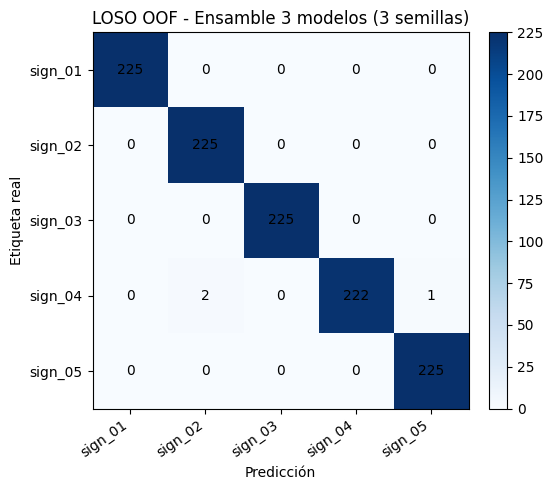

In [16]:
P_trans = np.mean(np.stack([oof_t_by_seed[s] for s in SEEDS]), axis=0)
P_cnn = np.mean(np.stack([oof_c_by_seed[s] for s in SEEDS]), axis=0)
P_lin = np.mean(np.stack([oof_l_by_seed[s] for s in SEEDS]), axis=0)
P_ens3 = (P_trans + P_cnn + P_lin) / 3.0

oof_pred = P_ens3.argmax(axis=1)
oof_scores = calculate_metrics(y, oof_pred)

fold_rows = []
for h in sorted(metadata.signer.unique()):
    mask = metadata.signer.to_numpy() == h
    fold_rows.append({
        'heldout_signer': h,
        'n_valid': int(mask.sum()),
        'Transformer': accuracy_score(y[mask], P_trans[mask].argmax(axis=1)),
        'CNN1D': accuracy_score(y[mask], P_cnn[mask].argmax(axis=1)),
        'Lineal_4Seg': accuracy_score(y[mask], P_lin[mask].argmax(axis=1)),
        'Ensamble_3M_Acc': accuracy_score(y[mask], oof_pred[mask]),
        'Ensamble_3M_F1': f1_score(y[mask], oof_pred[mask], average='macro', zero_division=0),
    })
oof_folds = pd.DataFrame(fold_rows)

print('>>> Transformer OOF:', calculate_metrics(y, P_trans.argmax(axis=1)))
print('>>> CNN1D OOF:      ', calculate_metrics(y, P_cnn.argmax(axis=1)))
print('>>> Lineal OOF:     ', calculate_metrics(y, P_lin.argmax(axis=1)))
print('>>> ENSAMBLE 3 MODELOS OOF Accuracy:', round(oof_scores['accuracy'], 6),
      '| Macro-F1:', round(oof_scores['macro_f1'], 6),
      '| Errores:', int((oof_pred != y).sum()), '/', len(y))
display(oof_folds)
print(classification_report(y, oof_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))
cm = print_confusion(y, oof_pred, 'LOSO OOF - Ensamble 3 modelos (3 semillas)')

## 11. Auditoría de errores (participante × vista × seña)

Desglosamos los errores OOF restantes por firmante, vista y clase en el conjunto público.

In [17]:
def public_error_audit(meta_df, y_true, pred, probs):
    df = meta_df[['video_id', 'signer', 'view', 'label']].copy()
    df['predicted_sign'] = [ID_TO_CLASS[int(i)] for i in pred]
    df['correct'] = (pred == y_true)
    df['confidence'] = probs.max(axis=1)
    counts = df.groupby(['signer', 'view', 'label']).agg(
        n=('correct', 'size'),
        errors=('correct', lambda x: int((~x).sum()))
    )
    counts['recall'] = 1.0 - counts['errors'] / counts['n']
    return df, counts.reset_index()

oof_details, errors_by_cell = public_error_audit(metadata, y, oof_pred, P_ens3)
print('Combinaciones con errores (entrenamiento público):')
display(errors_by_cell[errors_by_cell['errors'] > 0].sort_values(['errors', 'signer', 'view'], ascending=[False, True, True]))
print('Errores totales del ensamble:', int((oof_pred != y).sum()), '/', len(y))

Combinaciones con errores (entrenamiento público):


,signer,view,label,n,errors,recall
43,M04,V03,sign_04,25,3,0.88


Errores totales del ensamble: 3 / 1125


## 12. Guardar métricas, probabilidades OOF y configuración

Se guardan las probabilidades OOF individuales y del ensamble, las tablas por fold y la configuración completa en `OUT_DIR`.

In [18]:
all_results.to_csv(OUT_DIR / 'loso_per_seed_fold.csv', index=False)
oof_folds.to_csv(OUT_DIR / 'loso_ensemble_folds.csv', index=False)
oof_details.to_csv(OUT_DIR / 'oof_predictions_public.csv', index=False)
errors_by_cell.to_csv(OUT_DIR / 'public_errors_signer_view_class.csv', index=False)
np.save(OUT_DIR / 'oof_proba_transformer_mean.npy', P_trans)
np.save(OUT_DIR / 'oof_proba_cnn1d_mean.npy', P_cnn)
np.save(OUT_DIR / 'oof_proba_linear_mean.npy', P_lin)
np.save(OUT_DIR / 'oof_proba_ensemble_3models.npy', P_ens3)

selected_epochs = {
    'transformer': {str(s): [int(e) for e in ep_t_by_seed[s]] for s in SEEDS},
    'cnn1d': {str(s): [int(e) for e in ep_c_by_seed[s]] for s in SEEDS},
}
with open(OUT_DIR / 'selected_epochs.json', 'w', encoding='utf-8') as f:
    json.dump({'folds_order': sorted(metadata.signer.unique()), 'epochs': selected_epochs}, f, indent=2)

with open(OUT_DIR / 'experiment_config.json', 'w', encoding='utf-8') as f:
    json.dump({
        **CFG, 'config_tag': CFG_TAG, 'dataset_train_dir': str(TRAIN_LANDMARKS_DIR),
        'n_train': int(len(metadata)), 'classes': CLASS_NAMES,
        'params': {'transformer': p_trans, 'cnn1d': p_cnn, 'linear': p_lin, 'total': p_trans + p_cnn + p_lin},
        'oof_accuracy': oof_scores['accuracy'], 'oof_macro_f1': oof_scores['macro_f1'],
        'oof_errors': int((oof_pred != y).sum()),
    }, f, indent=2, ensure_ascii=False)

print('Artefactos de validación guardados en:', OUT_DIR)

Artefactos de validación guardados en: /kaggle/working/lsc5_t10_ens3_a8c94d8c1fad_medicion


## 14. Entrenamiento definitivo opcional con los tres participantes públicos

**Requiere `TRAIN_FINAL_MODEL=True`.** Se usa la mediana de las épocas LOSO interiores y se entrena cada semilla desde cero con `M02 + M03 + M04` y sus copias espejadas, guardando los 9 checkpoints `.pt` (3 modelos × 3 semillas).

In [19]:
FINAL_EPOCHS_TRANS = max(1, int(np.median([e for s in SEEDS for e in ep_t_by_seed[s]])))
FINAL_EPOCHS_CNN = max(1, int(np.median([e for s in SEEDS for e in ep_c_by_seed[s]])))
print(f'Épocas finales elegidas con LOSO interno -> Transformer: {FINAL_EPOCHS_TRANS} | CNN1D: {FINAL_EPOCHS_CNN} | Lineal: {LIN_EPOCHS}')

def save_checkpoint(payload, path):
    torch.save(payload, path)

if TRAIN_FINAL_MODEL:
    X_final = np.concatenate([X, X_mirror]) if MIRROR_AUG else X
    y_final = np.concatenate([y, y]) if MIRROR_AUG else y
    for s in SEEDS:
        t_net, t_scaler, _, hist = fit_seq_model(LSC5_Transformer, X_final, y_final, max_epochs=FINAL_EPOCHS_TRANS, patience=FINAL_EPOCHS_TRANS, seed=s + 999, lr=LR)
        save_history(hist, 'Transformer', s, s+999, 'final_train', '', '', FINAL_EPOCHS_TRANS)
        save_checkpoint({
            'model_state_dict': {k: v.detach().cpu() for k, v in t_net.state_dict().items()},
            'scaler_mean': torch.as_tensor(t_scaler['mean'].copy()),
            'scaler_std': torch.as_tensor(t_scaler['std'].copy()),
            'seed': int(s), 'final_epochs': int(FINAL_EPOCHS_TRANS), 'preprocess_version': PREPROCESS_VERSION
        }, OUT_DIR / f'lsc5_transformer_final_seed{s}.pt')

        c_net, c_scaler, _, hist = fit_seq_model(LSC5_CNN1D, X_final, y_final, max_epochs=FINAL_EPOCHS_CNN, patience=FINAL_EPOCHS_CNN, seed=s + 999, lr=1e-3)
        save_history(hist, 'CNN1D', s, s+999, 'final_train', '', '', FINAL_EPOCHS_CNN)
        save_checkpoint({
            'model_state_dict': {k: v.detach().cpu() for k, v in c_net.state_dict().items()},
            'scaler_mean': torch.as_tensor(c_scaler['mean'].copy()),
            'scaler_std': torch.as_tensor(c_scaler['std'].copy()),
            'seed': int(s), 'final_epochs': int(FINAL_EPOCHS_CNN), 'preprocess_version': PREPROCESS_VERSION
        }, OUT_DIR / f'lsc5_cnn1d_final_seed{s}.pt')

        l_net, hist = fit_linear_segment(X_final, y_final, seed=s + 999, epochs=LIN_EPOCHS, rotate_2d=True)
        save_history(hist, 'Linear4Seg_Rot2D', s, s+999, 'final_train', '', '', LIN_EPOCHS)
        save_checkpoint({
            'model_state_dict': {k: v.detach().cpu() for k, v in l_net.state_dict().items()},
            'in_dim': int(X_final.shape[2] * (N_SEGMENTS + 1)),
            'seed': int(s), 'lin_epochs': int(LIN_EPOCHS), 'preprocess_version': PREPROCESS_VERSION
        }, OUT_DIR / f'lsc5_linear_final_seed{s}.pt')

        print(f'Checkpoints finales guardados para seed={s} (Transformer + CNN1D + Lineal)')
else:
    print('Entrenamiento final deshabilitado; habilitar TRAIN_FINAL_MODEL=True tras revisar LOSO.')

Épocas finales elegidas con LOSO interno -> Transformer: 20 | CNN1D: 20 | Lineal: 50
Checkpoints finales guardados para seed=42 (Transformer + CNN1D + Lineal)
Checkpoints finales guardados para seed=7 (Transformer + CNN1D + Lineal)
Checkpoints finales guardados para seed=123 (Transformer + CNN1D + Lineal)


## Medición final y curvas por época
Las curvas de validación pertenecen exclusivamente a las particiones internas. Los entrenamientos externos y definitivos registran solo métricas de entrenamiento. La accuracy de entrenamiento se mide sobre lotes aumentados en modo train, y no es directamente comparable con accuracy de validación en modo eval.

{
  "timestamp_utc_start": "2026-11-26T01:22:22.914902+00:00",
  "device": "cpu",
  "torch_version": "2.11.0+cpu",
  "python_version": "3.13.18",
  "system": "Linux",
  "cpu_threads_pytorch": 4,
  "num_workers": 0,
  "peak_python_rss_mib": 1333.1328125,
  "measurement_elapsed_seconds": 4255.025108889,
  "loso_elapsed_seconds_including_history_io": 3519.1100964546204,
  "train_final_model": true,
  "scope": "Nueva corrida instrumentada; RSS del proceso Python, no RAM total del host. VRAM de PyTorch desde reinicio de contadores."
}


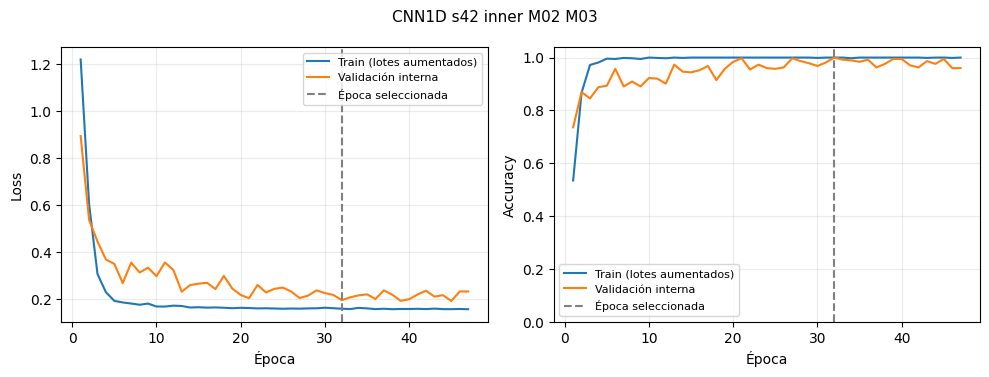

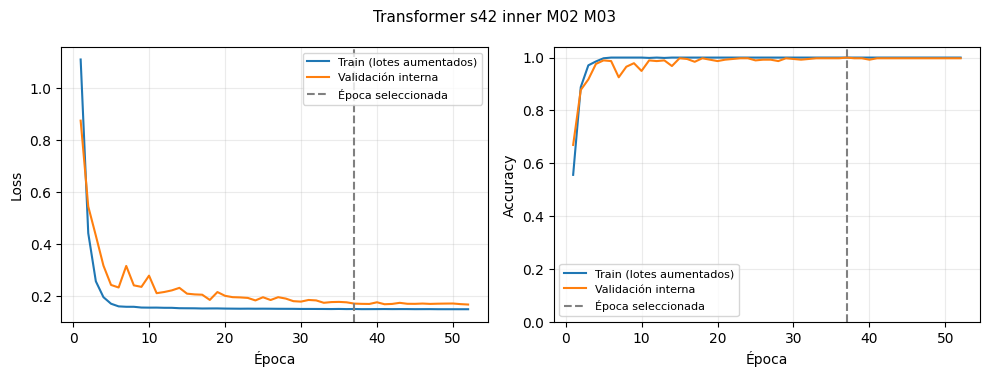

Historiales guardados: 72 | Filas por época: 2527
Evidencias: /kaggle/working/lsc5_t10_ens3_a8c94d8c1fad_medicion


In [20]:
# Capturar los picos ANTES de generar gráficas y empaquetar archivos.
# ru_maxrss en Linux se expresa en KiB: pico RSS del kernel Python desde su inicio.
if DEVICE.type == 'cuda':
    torch.cuda.synchronize(DEVICE)
resources = {
    'timestamp_utc_start': MEASUREMENT_DATE,
    'device': str(DEVICE), 'torch_version': torch.__version__,
    'python_version': platform.python_version(),
    'system': platform.system(),
    'cpu_threads_pytorch': torch.get_num_threads(),
    'num_workers': NUM_WORKERS,
    'peak_python_rss_mib': resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024,
    'measurement_elapsed_seconds': time.perf_counter() - MEASUREMENT_START,
    'loso_elapsed_seconds_including_history_io': LOSO_ELAPSED_SECONDS,
    'train_final_model': TRAIN_FINAL_MODEL,
    'scope': 'Nueva corrida instrumentada; RSS del proceso Python, no RAM total del host. VRAM de PyTorch desde reinicio de contadores.'
}
if DEVICE.type == 'cuda':
    resources.update({'gpu': torch.cuda.get_device_name(DEVICE),
        'gpu_peak_allocated_mib': torch.cuda.max_memory_allocated(DEVICE) / 2**20,
        'gpu_peak_reserved_mib': torch.cuda.max_memory_reserved(DEVICE) / 2**20})
(OUT_DIR / 'recursos_kaggle.json').write_text(json.dumps(resources, indent=2), encoding='utf-8')
print(json.dumps(resources, indent=2))

# Consolidar historiales y generar gráficas. No evaluar el fold externo por época.
frames = [pd.read_csv(p, keep_default_na=False, na_values=['']) for p in sorted(HISTORY_DIR.glob('*.csv'))]
assert frames, 'No hay historiales: ejecuta primero el LOSO.'
history_all = pd.concat(frames, ignore_index=True)
history_all.to_csv(OUT_DIR / 'historial_entrenamiento.csv', index=False)
CURVE_DIR = OUT_DIR / 'curvas'
CURVE_DIR.mkdir(exist_ok=True)

# Una figura por entrenamiento: validación interna si existe; en el resto solo train.
for file in sorted(HISTORY_DIR.glob('*.csv')):
    h = pd.read_csv(file, keep_default_na=False)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
    ax[0].plot(h.epoch, h.train_loss, label='Train (lotes aumentados)')
    ax[1].plot(h.epoch, h.train_accuracy, label='Train (lotes aumentados)')
    if 'val_loss' in h.columns:
        ax[0].plot(h.epoch, h.val_loss, label='Validación interna')
        ax[1].plot(h.epoch, h.val_accuracy, label='Validación interna')
        for a in ax:
            a.axvline(h.selected_or_fixed_epoch.iloc[0], ls='--', color='gray', label='Época seleccionada')
    for a, label in zip(ax, ['Loss', 'Accuracy']):
        a.set(xlabel='Época', ylabel=label)
        a.grid(alpha=.25); a.legend(fontsize=8)
    ax[1].set_ylim(0, 1.04)
    fig.suptitle(file.stem.replace('_', ' '), fontsize=11)
    fig.tight_layout()
    fig.savefig(CURVE_DIR / f'{file.stem}.png', dpi=160, bbox_inches='tight')
    # Mostrar en notebook dos ejemplos predefinidos, sin seleccionar por resultado.
    if file.stem in ['Transformer_s42_inner_M02_M03', 'CNN1D_s42_inner_M02_M03']:
        plt.show()
    plt.close(fig)
print('Historiales guardados:', len(frames), '| Filas por época:', len(history_all))
print('Evidencias:', OUT_DIR)


## Empaquetar resultados

Se guardan historiales, gráficas, recursos y artefactos de esta reproducción en un ZIP separado. No contiene predicciones del test.

In [21]:
def package_artifacts(out_dir=OUT_DIR):
    out_dir = Path(out_dir)
    zip_path = out_dir.parent / f'{out_dir.name}_artifacts.zip'
    with zipfile.ZipFile(zip_path, 'w', compression=zipfile.ZIP_DEFLATED) as z:
        for p in sorted(out_dir.rglob('*')):
            if p.is_file():
                z.write(p, arcname=p.relative_to(out_dir))
    return zip_path

archive = package_artifacts()
print('ZIP de artefactos:', archive)
print('Total archivos en la carpeta:', len(list(OUT_DIR.glob('*'))))

ZIP de artefactos: /kaggle/working/lsc5_t10_ens3_a8c94d8c1fad_medicion_artifacts.zip
Total archivos en la carpeta: 25
